# 01 — Test ViTPose on One Video
**Goal:** load your existing checkpoint and verify one frame before processing a dataset.  
Prerequisite: create `src/vitpose_model.py` using the instructions in `README.md`.

In [2]:

from pathlib import Path
import sys

PROJECT_DIR = Path(
    r"C:\Users\admin\ViTPose_Action_Recognition"
)

sys.path.insert(0, str(PROJECT_DIR))

from src.vitpose_model import (
    ViTPose,
    get_affine_transform,
    decode_heatmaps,
    draw_skeleton_on,
    IMG_H,
    IMG_W,
    IMG_MEAN,
    IMG_STD,
)

print("ViTPose module imported successfully!")
print("Input dimensions:", IMG_H, "x", IMG_W)
print("Project directory:", PROJECT_DIR)


ViTPose module imported successfully!
Input dimensions: 256 x 192
Project directory: C:\Users\admin\ViTPose_Action_Recognition


In [2]:
%pip install ultralytics opencv-python matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
import sys, json
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT_DIR = Path(
    r"C:\Users\admin\ViTPose_Action_Recognition"
)
sys.path.insert(0, str(PROJECT_DIR))
from src.vitpose_model import (
    ViTPose, get_affine_transform, decode_heatmaps, draw_skeleton_on,
    IMG_H, IMG_W, IMG_MEAN, IMG_STD
)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / "epoch_209.pth"
assert CHECKPOINT_PATH.exists(), f"Checkpoint not found: {CHECKPOINT_PATH.resolve()}"

checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
model = ViTPose().to(DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()

print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())
print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))

Device: cuda:0
CUDA available: True
Checkpoint epoch: 209


In [4]:
DATA_DIR = PROJECT_DIR / "data" / "raw" / "ucf_sports"
VIDEO_EXTS = {".avi", ".mp4", ".mpeg", ".mpg", ".mov"}
videos = sorted(p for p in DATA_DIR.rglob("*") if p.is_file() and p.suffix.lower() in VIDEO_EXTS)
assert videos, f"No videos found under {DATA_DIR}"
VIDEO_PATH = videos[0]  # Change this to a specific path after the first test
print("Testing:", VIDEO_PATH)

detector = YOLO("yolo11n.pt")  # Downloads model weights the first time if not cached

Testing: C:\Users\admin\ViTPose_Action_Recognition\data\raw\ucf_sports\ApplyEyeMakeup\v_ApplyEyeMakeup_g01_c01.avi


In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("NumPy imported successfully")
print("Matplotlib imported successfully")


OpenCV version: 4.13.0
NumPy imported successfully
Matplotlib imported successfully


In [4]:

from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\admin\ViTPose_Action_Recognition"
)

DATA_DIR = PROJECT_DIR / "data" / "raw" / "ucf_sports"

videos = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".avi", ".mp4", ".mpeg", ".mpg", ".mov"}
)

print("Dataset folder exists:", DATA_DIR.exists())
print("Videos found:", len(videos))

assert len(videos) > 0, (
    f"No videos found. Check dataset path: {DATA_DIR}"
)

VIDEO_PATH = videos[0]

print("Selected video:", VIDEO_PATH)


Dataset folder exists: True
Videos found: 13320
Selected video: C:\Users\admin\ViTPose_Action_Recognition\data\raw\ucf_sports\ApplyEyeMakeup\v_ApplyEyeMakeup_g01_c01.avi


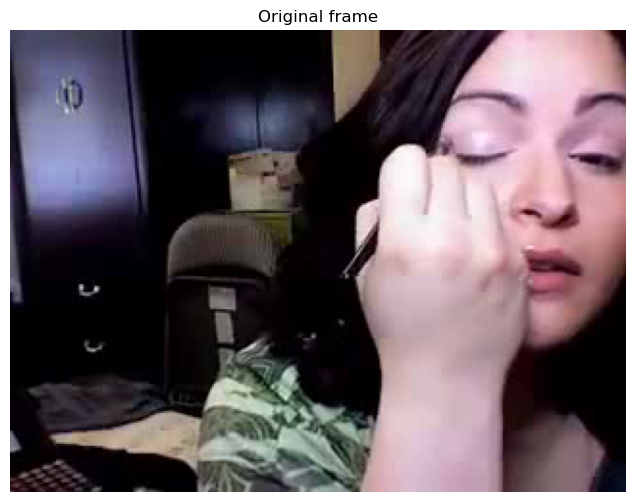

In [5]:
cap = cv2.VideoCapture(str(VIDEO_PATH))
assert cap.isOpened(), f"Cannot open {VIDEO_PATH}"
ok, frame_bgr = cap.read()
cap.release()
assert ok, "Could not read first frame"
frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(frame_rgb)
plt.axis("off")
plt.title("Original frame")
plt.show()

In [7]:

from ultralytics import YOLO

detector = YOLO("yolo11n.pt")

print("YOLO detector loaded successfully!")


YOLO detector loaded successfully!


In [35]:
print("IMG_H exists:", "IMG_H" in globals())
print("IMG_W exists:", "IMG_W" in globals())
print("ViTPose model exists:", "model" in globals())

IMG_H exists: True
IMG_W exists: True
ViTPose model exists: True


In [36]:

import sys
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

print("Project root:", PROJECT_DIR)
print("Model file exists:", (PROJECT_DIR / "src" / "vitpose_model.py").exists())


Project root: C:\Users\admin\ViTPose_Action_Recognition
Model file exists: True


In [37]:
from src.vitpose_model import IMG_H, IMG_W

print("Image height:", IMG_H)
print("Image width:", IMG_W)

Image height: 256
Image width: 192


In [38]:
from src.vitpose_model import get_affine_transform

print("Affine transformation function imported successfully!")

Affine transformation function imported successfully!


In [39]:

from src.vitpose_model import IMG_MEAN, IMG_STD

print("IMG_MEAN:", IMG_MEAN)
print("IMG_STD:", IMG_STD)


IMG_MEAN: [0.485 0.456 0.406]
IMG_STD: [0.229 0.224 0.225]


In [40]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch version: 2.7.1+cu118
CUDA available: True


In [41]:

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [42]:

import torch
from pathlib import Path
from src.vitpose_model import ViTPose

# Paths and device
PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" / "epoch_209.pth"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the model
model = ViTPose()

# Load trained weights
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(checkpoint["model_state"], strict=True)
model = model.to(DEVICE)
model.eval()

print("Trained ViTPose checkpoint loaded successfully!")
print("Device:", DEVICE)
print("Checkpoint epoch:", checkpoint.get("epoch", "not recorded"))


Trained ViTPose checkpoint loaded successfully!
Device: cuda
Checkpoint epoch: 209


In [66]:
import importlib
import src.vitpose_model as vitpose_utils

importlib.reload(vitpose_utils)

decode_heatmaps = vitpose_utils.decode_heatmaps
draw_skeleton_on = vitpose_utils.draw_skeleton_on
get_affine_transform = vitpose_utils.get_affine_transform

print("Updated pose helper functions loaded!")

Updated pose helper functions loaded!


People detected: 1
Heatmaps: (17, 64, 48)
Keypoints: (17, 3)


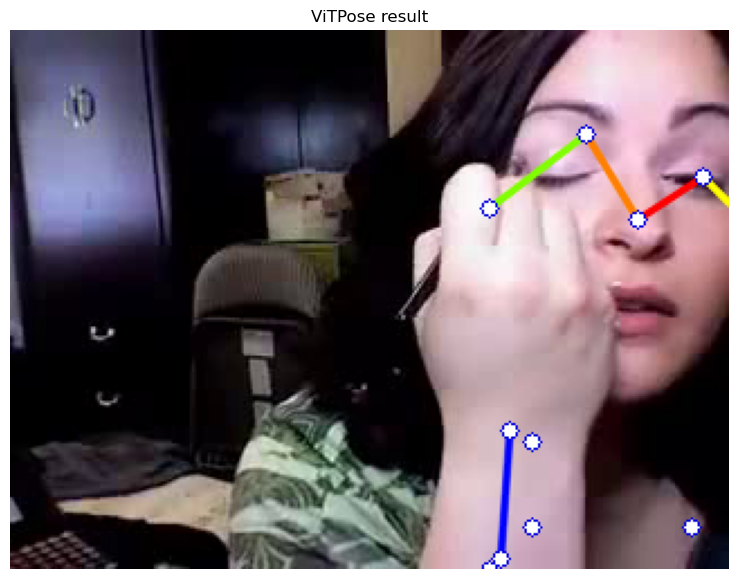

In [67]:
det = detector.predict(frame_bgr, classes=[0], conf=0.30, verbose=False)[0]
print("People detected:", len(det.boxes))

if len(det.boxes) == 0:
    raise RuntimeError("No person detected. Try another video/frame or lower conf to 0.20.")

boxes = det.boxes.xyxy.cpu().numpy()
areas = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
x1, y1, x2, y2 = boxes[np.argmax(areas)]

center = np.array([(x1+x2)/2, (y1+y2)/2], dtype=np.float32)
box_w, box_h = x2-x1, y2-y1
scale = max(box_w, box_h * IMG_W / IMG_H) * 1.25
trans = get_affine_transform(center, scale, 0.0, (IMG_W, IMG_H))
crop = cv2.warpAffine(frame_rgb, trans, (IMG_W, IMG_H))
crop = crop.astype(np.float32) / 255.0
crop = (crop - IMG_MEAN) / IMG_STD
tensor = torch.from_numpy(crop.transpose(2,0,1).copy()).float().unsqueeze(0).to(DEVICE)

with torch.no_grad():
    heatmaps = model(tensor)[0].float().cpu().numpy()

print("Heatmaps:", heatmaps.shape)  # expected (17, 64, 48)
keypoints = decode_heatmaps(heatmaps, center, scale)
print("Keypoints:", keypoints.shape)  # expected (17, 3), columns x,y,confidence

pose_rgb = draw_skeleton_on(frame_rgb.copy(), keypoints, thresh=0.1)
plt.figure(figsize=(12, 7))
plt.imshow(pose_rgb)
plt.axis("off")
plt.title("ViTPose result")
plt.show()

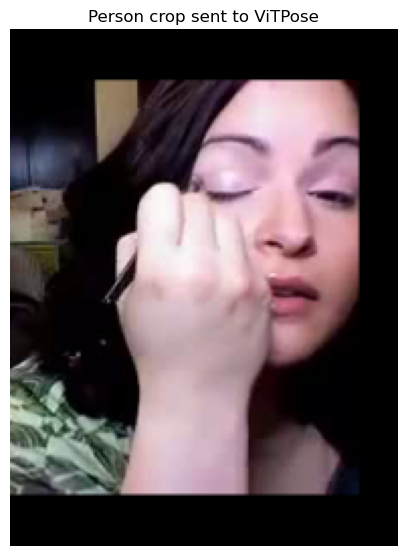

In [68]:
crop_display = cv2.warpAffine(
    frame_rgb,
    trans,
    (IMG_W, IMG_H)
)

plt.figure(figsize=(5, 7))
plt.imshow(crop_display)
plt.axis("off")
plt.title("Person crop sent to ViTPose")
plt.show()

In [69]:
print("Heatmap range:", heatmaps.min(), heatmaps.max())
print("Mean confidence:", keypoints[:, 2].mean())
print("Keypoint confidences:")
print(np.round(keypoints[:, 2], 3))

Heatmap range: -0.01709026 0.96444744
Mean confidence: 0.38695544
Keypoint confidences:
[0.902 0.964 0.616 0.673 0.739 0.703 0.049 0.066 0.177 0.417 0.485 0.022
 0.321 0.042 0.054 0.171 0.176]


In [70]:
print("Original frame size (H, W):", frame_rgb.shape[:2])
print("Model input size (H, W):", crop.shape[:2])
print("Center:", center)
print("Scale:", scale)
print("Affine transform:\n", trans)

Original frame size (H, W): (240, 320)
Model input size (H, W): (256, 192)
Center: [230.47601  120.186844]
Scale: 224.54529
Affine transform:
 [[ 8.55061392e-01 -0.00000000e+00 -1.01071141e+02]
 [-1.54146786e-17  8.55061392e-01  2.52328700e+01]]


In [71]:

# Inspect all 17 predicted body keypoints
print("Keypoint predictions:")
print("Index | X | Y | Confidence")

for i, (x, y, conf) in enumerate(keypoints):
    print(f"{i:2d} | {x:7.2f} | {y:7.2f} | {conf:.3f}")


Keypoint predictions:
Index | X | Y | Confidence
 0 |  279.79 |   84.10 | 0.902
 1 |  308.31 |   65.16 | 0.964
 2 |  256.03 |   46.23 | 0.616
 3 |  327.32 |   84.10 | 0.673
 4 |  213.26 |   79.37 | 0.739
 5 |  303.56 |  221.38 | 0.703
 6 |  122.96 |  169.31 | 0.049
 7 |  232.27 |  221.38 | 0.066
 8 |  218.01 |  235.58 | 0.177
 9 |  232.27 |  183.51 | 0.417
10 |  222.76 |  178.77 | 0.485
11 |  279.79 |  126.70 | 0.022
12 |  213.26 |  240.31 | 0.321
13 |  218.01 |   88.83 | 0.042
14 |  213.26 |  230.84 | 0.054
15 |  232.27 |  221.38 | 0.171
16 |  213.26 |  240.31 | 0.176


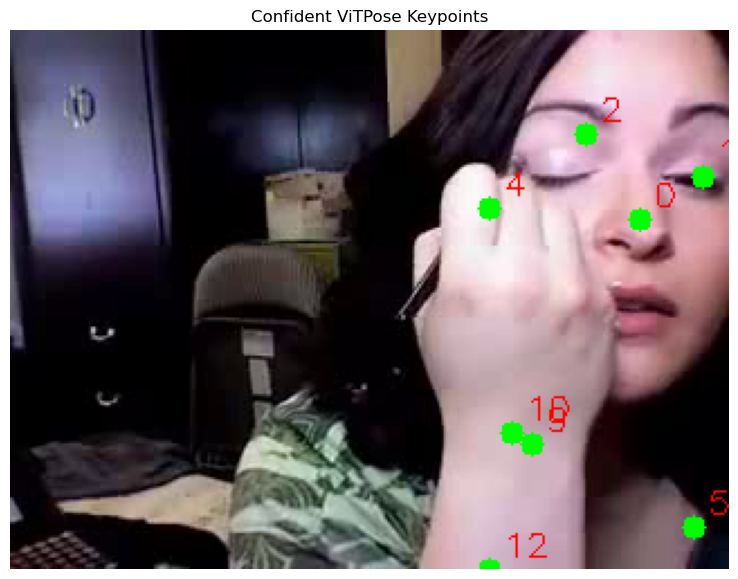

In [72]:

# Visualize only confident keypoints
CONF_THRESHOLD = 0.30

pose_filtered = frame_rgb.copy()

for i, (x, y, conf) in enumerate(keypoints):
    if conf >= CONF_THRESHOLD:
        cv2.circle(
            pose_filtered,
            (int(round(x)), int(round(y))),
            5,
            (0, 255, 0),
            -1
        )
        cv2.putText(
            pose_filtered,
            str(i),
            (int(round(x)) + 6, int(round(y)) - 6),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (255, 0, 0),
            1
        )

plt.figure(figsize=(10, 7))
plt.imshow(pose_filtered)
plt.axis("off")
plt.title("Confident ViTPose Keypoints")
plt.show()


In [73]:
OUT_DIR = PROJECT_DIR / "outputs" / "pose_videos"
OUT_DIR.mkdir(parents=True, exist_ok=True)
image_path = OUT_DIR / f"{VIDEO_PATH.stem}_first_frame_pose.jpg"
cv2.imwrite(str(image_path), cv2.cvtColor(pose_rgb, cv2.COLOR_RGB2BGR))
print("Saved image:", image_path.resolve())

Saved image: C:\Users\admin\ViTPose_Action_Recognition\outputs\pose_videos\v_ApplyEyeMakeup_g01_c01_first_frame_pose.jpg


In [74]:

from pathlib import Path

checkpoint_dir = Path(r"C:\Users\admin\ViTPose_Action_Recognition\checkpoints")

print("Folder exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    files = list(checkpoint_dir.rglob("*"))
    if files:
        for file in files:
            print(file.relative_to(checkpoint_dir))
    else:
        print("The checkpoints folder is empty.")


Folder exists: True
epoch_209.pth


In [75]:

import torch
from pathlib import Path

checkpoint_path = Path(
    r"C:\Users\admin\ViTPose_Action_Recognition\checkpoints\epoch_209.pth"
)

print("Checkpoint exists:", checkpoint_path.exists())
print("Checkpoint size (MB):", round(checkpoint_path.stat().st_size / (1024**2), 2))

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"\n{key}:")
            print("Number of entries:", len(value))
            print("First keys:", list(value.keys())[:10])


Checkpoint exists: True
Checkpoint size (MB): 1030.09
Checkpoint type: <class 'dict'>
Checkpoint keys: ['epoch', 'model_state', 'optimizer_state', 'scheduler_state', 'loss', 'train_losses']

model_state:
Number of entries: 163
First keys: ['encoder.patch_embed.pos_embed', 'encoder.patch_embed.proj.weight', 'encoder.patch_embed.proj.bias', 'encoder.blocks.0.norm1.weight', 'encoder.blocks.0.norm1.bias', 'encoder.blocks.0.attn.qkv.weight', 'encoder.blocks.0.attn.qkv.bias', 'encoder.blocks.0.attn.out_proj.weight', 'encoder.blocks.0.attn.out_proj.bias', 'encoder.blocks.0.norm2.weight']

optimizer_state:
Number of entries: 2
First keys: ['state', 'param_groups']

scheduler_state:
Number of entries: 6
First keys: ['base_lrs', 'last_epoch', '_step_count', '_get_lr_called_within_step', '_last_lr', 'lr_lambdas']


In [76]:

import torch
from src.vitpose_model import ViTPose

checkpoint = torch.load(
    r"C:\Users\admin\ViTPose_Action_Recognition\checkpoints\epoch_209.pth",
    map_location="cpu",
    weights_only=False
)

model = ViTPose()
model_state = model.state_dict()
checkpoint_state = checkpoint["model_state"]

model_keys = set(model_state.keys())
checkpoint_keys = set(checkpoint_state.keys())

matching_keys = model_keys & checkpoint_keys
shape_matches = [
    key for key in matching_keys
    if model_state[key].shape == checkpoint_state[key].shape
]

print("Model parameters:", len(model_keys))
print("Checkpoint parameters:", len(checkpoint_keys))
print("Matching names:", len(matching_keys))
print("Matching names and shapes:", len(shape_matches))

print("\nModel-only keys (first 10):")
print(list(model_keys - checkpoint_keys)[:10])

print("\nCheckpoint-only keys (first 10):")
print(list(checkpoint_keys - model_keys)[:10])

print("\nShape mismatches (first 10):")
print([
    (key, tuple(model_state[key].shape),
     tuple(checkpoint_state[key].shape))
    for key in matching_keys
    if model_state[key].shape != checkpoint_state[key].shape
][:10])


Model parameters: 163
Checkpoint parameters: 163
Matching names: 163
Matching names and shapes: 163

Model-only keys (first 10):
[]

Checkpoint-only keys (first 10):
[]

Shape mismatches (first 10):
[]


Heatmap shape: (17, 64, 48)
All finite: True
Overall min: -0.01709026
Overall max: 0.96444744
Overall mean: 0.0034376832
Overall std: 0.034133703
Joint 00: peak=(34, 24), max=0.9022, std=0.0598
Joint 01: peak=(40, 20), max=0.9644, std=0.0677
Joint 02: peak=(29, 16), max=0.6162, std=0.0480
Joint 03: peak=(44, 24), max=0.6732, std=0.0438
Joint 04: peak=(20, 23), max=0.7392, std=0.0553
Joint 05: peak=(39, 53), max=0.7028, std=0.0470
Joint 06: peak=(01, 42), max=0.0490, std=0.0020
Joint 07: peak=(24, 53), max=0.0664, std=0.0027
Joint 08: peak=(21, 56), max=0.1774, std=0.0097
Joint 09: peak=(24, 45), max=0.4171, std=0.0255
Joint 10: peak=(22, 44), max=0.4845, std=0.0296
Joint 11: peak=(34, 33), max=0.0221, std=0.0010
Joint 12: peak=(20, 57), max=0.3207, std=0.0145
Joint 13: peak=(21, 25), max=0.0422, std=0.0027
Joint 14: peak=(20, 55), max=0.0536, std=0.0032
Joint 15: peak=(24, 53), max=0.1707, std=0.0076
Joint 16: peak=(20, 57), max=0.1763, std=0.0090


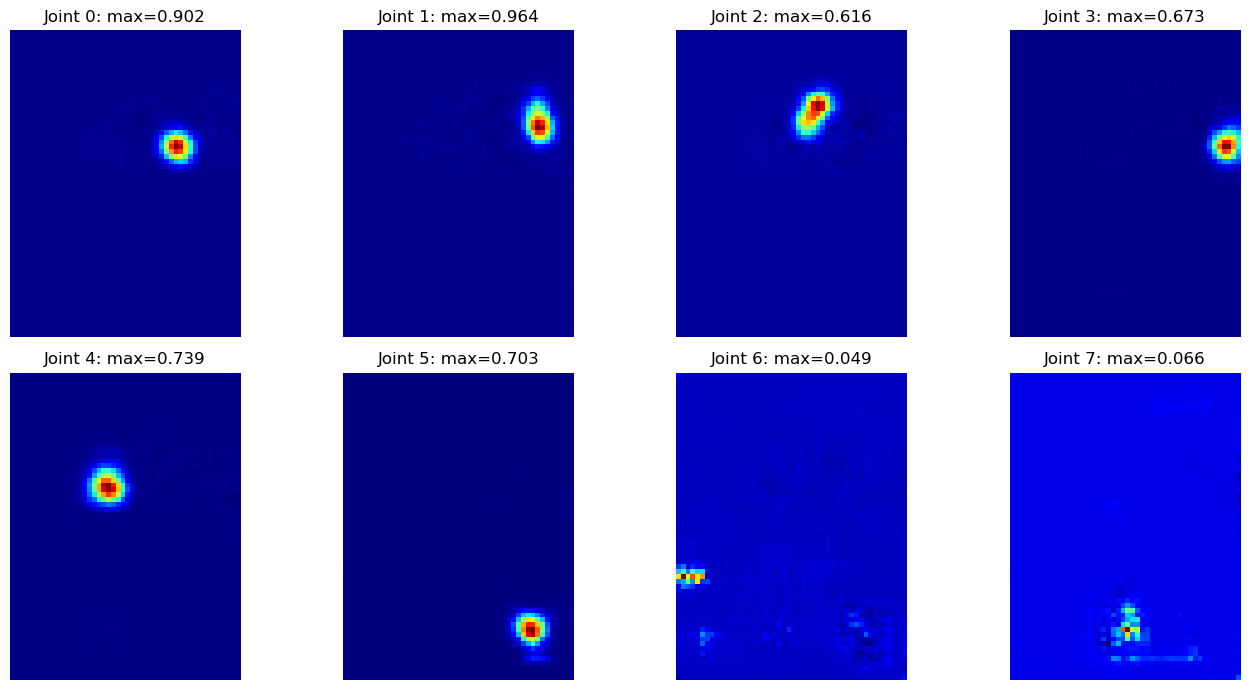

In [77]:

# Diagnose the raw ViTPose heatmaps before decoding
print("Heatmap shape:", heatmaps.shape)
print("All finite:", np.isfinite(heatmaps).all())
print("Overall min:", np.min(heatmaps))
print("Overall max:", np.max(heatmaps))
print("Overall mean:", np.mean(heatmaps))
print("Overall std:", np.std(heatmaps))

# Inspect each of the 17 joints
for j in range(heatmaps.shape[0]):
    hm = heatmaps[j]
    iy, ix = np.unravel_index(np.argmax(hm), hm.shape)

    print(
        f"Joint {j:02d}: "
        f"peak=({ix:02d}, {iy:02d}), "
        f"max={hm[iy, ix]:.4f}, "
        f"std={np.std(hm):.4f}"
    )

# Display several raw heatmaps
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for j, ax in enumerate(axes.flat):
    ax.imshow(heatmaps[j], cmap="jet")
    ax.set_title(f"Joint {j}: max={heatmaps[j].max():.3f}")
    ax.axis("off")

plt.tight_layout()
plt.show()
